# CSC311 Project

### Phase 1: Data Exploration

In [2]:
import numpy as np
import pandas as pd

#### 1. Data Set Split

In [19]:
def split_by_student(ids, val_frac=0.2, test_frac=0.2, seed=42):
    """
    Splits the unique student ids into train/val/test groups. All three rows
    from the same student end up in the same split, so the model is never
    tested on a student it has already seen during training.
    """
    rng = np.random.default_rng(seed)
    students = rng.permutation(ids.unique())
    n_test = int(len(students) * test_frac)
    n_val = int(len(students) * val_frac)
    test_ids = students[:n_test]
    val_ids = students[n_test:n_test + n_val]
    train_ids = students[n_test + n_val:]
    return ids.isin(train_ids), ids.isin(val_ids), ids.isin(test_ids)

datadir = '../data/'
dataset = 'csc311_project_training_202609.csv'
df = pd.read_csv(datadir + dataset)

column_mapping = {
    'How easy do you think it would be for someone with no prior experience to start playing this sport recreationally? Rate it on a scale from 0 to 10, where 0 means extremely difficult and 10 means extremely easy.': 'ease_of_play',
    'Success in this sport depends heavily on strategy and planning.': 'strategy_dependent',
    'Players must be comfortable with a high risk of injury.': 'injury_risk',
    'Individual brilliance can outweigh teamwork in this sport.': 'individual_brilliance',
    'Where might you play this sport?': 'locations',
    'During which seasons would you be most likely to play this sport recreationally in Toronto?': 'seasons',
    'What types of music do you most associate with this sport?': 'music_genre',
    'What foods and drinks do you associate with watching this sport in the place or culture you know best?': 'food_drink',
    'What colour do you associate with this sport?': 'color',
    'Which song do you associate with this sport?': 'song',
    'How do you feel when you watch this sport?': 'emotions',
    'How much would you be willing to pay for a decent seat at a professional competition of this sport?': 'ticket_price'
}
df = df.rename(columns=column_mapping)
print("Column renamed to: " + str(df.columns.tolist()))

train_mask, val_mask, test_mask = split_by_student(df['id'])

train_df = df[train_mask].copy()
val_df = df[val_mask].copy()
test_df = df[test_mask].copy()

print(f"Total rows: {len(df)}")
print(f"Train rows: {len(train_df)}")
print(f"Validation rows: {len(val_df)}")
print(f"Test rows: {len(test_df)}")

train_df.to_csv(datadir + 'raw/train.csv', index=False)
val_df.to_csv(datadir + 'raw/val.csv', index=False)
test_df.to_csv(datadir + 'raw/test.csv', index=False)

print("Datasets successfully saved to data/raw/")

Column renamed to: ['id', 'ease_of_play', 'strategy_dependent', 'injury_risk', 'individual_brilliance', 'locations', 'seasons', 'music_genre', 'food_drink', 'color', 'song', 'emotions', 'ticket_price', 'label']
Total rows: 870
Train rows: 522
Validation rows: 174
Test rows: 174
Datasets successfully saved to data/raw/


In [16]:
train_df = pd.read_csv('../data/raw/train.csv')

train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     522 non-null    int64  
 1   ease_of_play           517 non-null    float64
 2   strategy_dependent     516 non-null    object 
 3   injury_risk            517 non-null    object 
 4   individual_brilliance  516 non-null    object 
 5   locations              517 non-null    object 
 6   seasons                517 non-null    object 
 7   music_genre            517 non-null    object 
 8   food_drink             508 non-null    object 
 9   color                  513 non-null    object 
 10  song                   479 non-null    object 
 11  emotions               516 non-null    object 
 12  ticket_price           515 non-null    object 
 13  label                  522 non-null    object 
dtypes: float64(1), int64(1), object(12)
memory usage: 57.2+ KB

#### 2. Feature Distributions

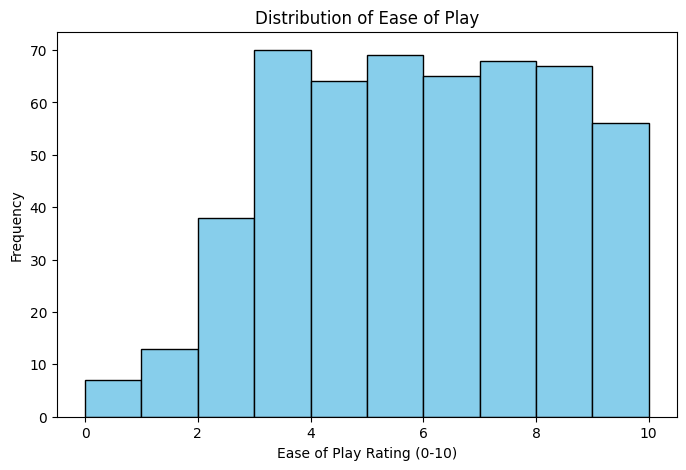

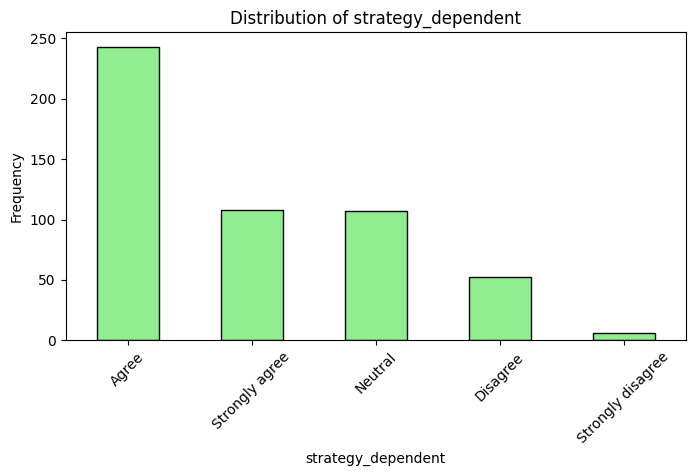

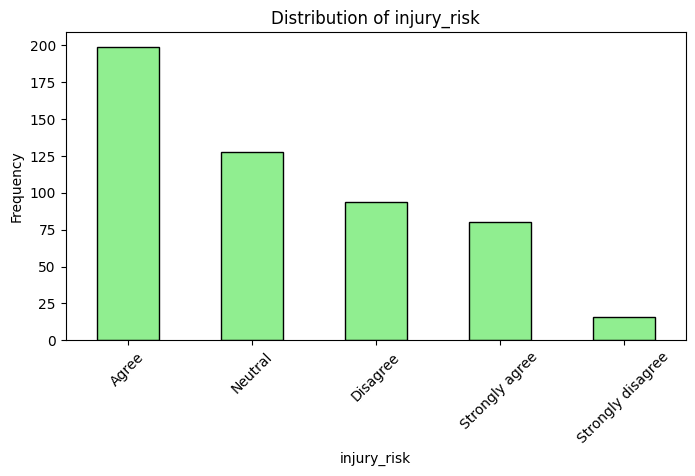

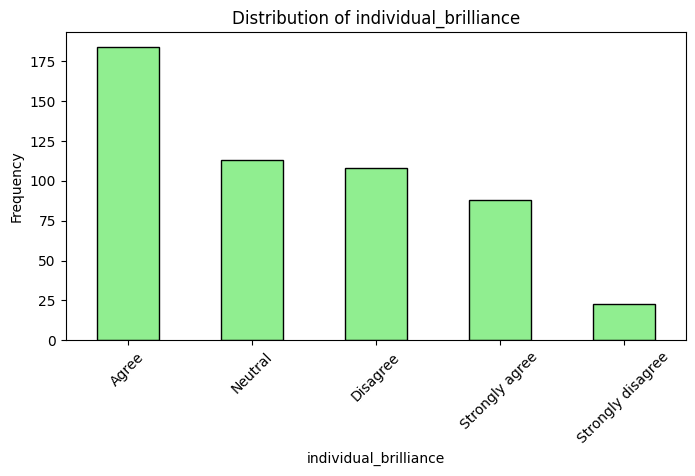

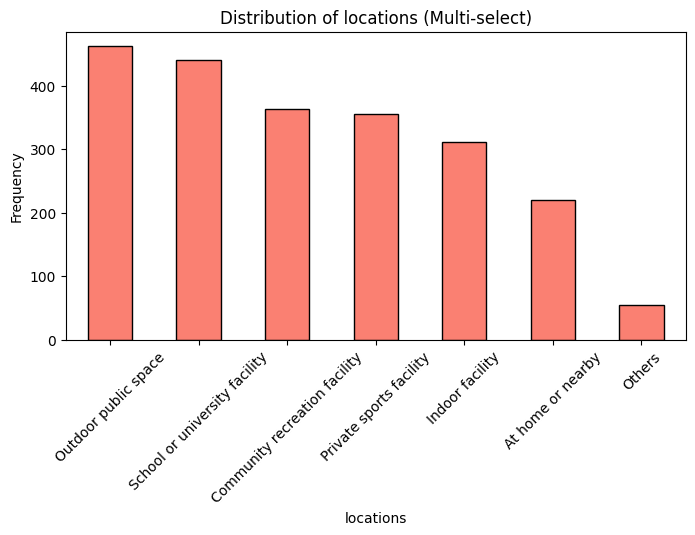

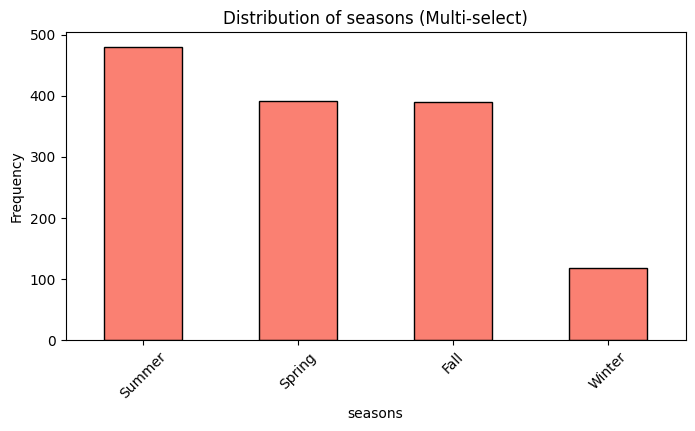

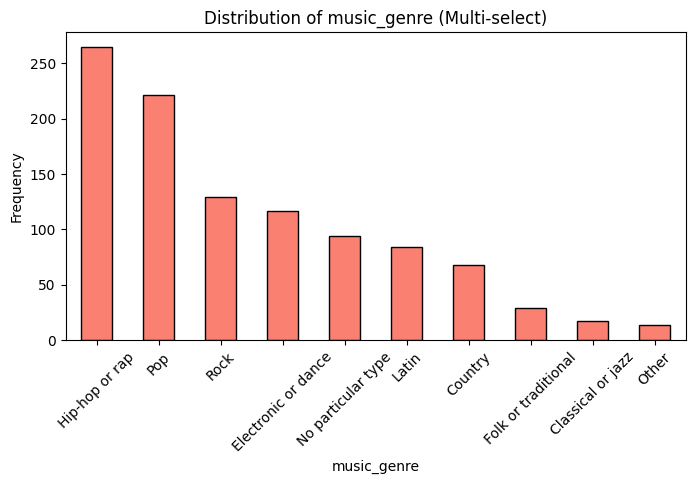

In [4]:
import matplotlib.pyplot as plt

# 1. Histogram for Continuous/Numeric Data
plt.figure(figsize=(8, 5))
# bins=10 works well since the scale is 0 to 10
train_df['ease_of_play'].plot(kind='hist', bins=10, edgecolor='black', color='skyblue')
plt.title('Distribution of Ease of Play')
plt.xlabel('Ease of Play Rating (0-10)')
plt.ylabel('Frequency')
plt.show()

# 2. Bar Charts for Categorical (Likert Scale) Data
likert_cols = ['strategy_dependent', 'injury_risk', 'individual_brilliance']

for col in likert_cols:
    plt.figure(figsize=(8, 4))
    # Count the frequencies of each category and plot
    train_df[col].value_counts().plot(kind='bar', color='lightgreen', edgecolor='black')
    plt.title(f'Distribution of {col}')
    plt.ylabel('Frequency')
    plt.xticks(rotation=45) # Rotate text so it doesn't overlap
    plt.show()

# 3. Bar Charts for Multi-Select Data
multiselect_cols = ['locations', 'seasons', 'music_genre']

for col in multiselect_cols:
    plt.figure(figsize=(8, 4))
    
    # Step A: Drop missing values so the string method doesn't crash
    # Step B: Split the string by commas (e.g., "Winter,Spring" -> ["Winter", "Spring"])
    # Step C: Explode the list into separate rows
    # Step D: Strip any accidental whitespace
    exploded_data = train_df[col].dropna().str.split(',').explode().str.strip()
    
    # Now that they are separated, count and plot them just like categorical data
    exploded_data.value_counts().plot(kind='bar', color='salmon', edgecolor='black')
    plt.title(f'Distribution of {col} (Multi-select)')
    plt.ylabel('Frequency')
    plt.xticks(rotation=45)
    plt.show()

#### 3. Class Imbalance

In [22]:
print("\n--- Target Label Distribution (%) ---")
imbalance = train_df['label'].value_counts(normalize=True) * 100
print(imbalance)


--- Target Label Distribution (%) ---
label
Soccer        33.333333
Baseball      33.333333
Basketball    33.333333
Name: proportion, dtype: float64


No imbalance has found.

#### 4. Handle Missing Values & Feature Engineering

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Define feature categories
numerical_cols = ['ease_of_play', 'ticket_price']
likert_cols = ['strategy_dependent', 'injury_risk', 'individual_brilliance']
multiselect_cols = ['locations', 'seasons', 'music_genre']
free_text_cols = ['food_drink', 'color', 'song', 'emotions']

# 2. Standardize missing markers
custom_missing = ["-", "none", "[]", " "]
train_df = train_df.replace(custom_missing, np.nan)

# 3. Parse text to numbers (Ticket Price)
extracted_prices = train_df['ticket_price'].astype(str).str.extract(r'(\d+\.?\d*)')[0]
train_df['ticket_price'] = pd.to_numeric(extracted_prices, errors='coerce')

# 4. Impute missing values
train_df[numerical_cols] = train_df[numerical_cols].fillna(train_df[numerical_cols].median())
train_df[likert_cols + multiselect_cols] = train_df[likert_cols + multiselect_cols].fillna('NULL')
train_df[free_text_cols] = train_df[free_text_cols].fillna('')

# 5. Ordinal encode Likert scales
likert_mapping = {
    'NULL': 0,
    'Strongly disagree': 1,
    'Disagree': 2,
    'Neutral': 3,
    'Agree': 4,
    'Strongly agree': 5
}
for col in likert_cols:
    train_df[col] = train_df[col].map(likert_mapping).fillna(0).astype(int)

# 6. Multi-hot encode multiselect features
for col in multiselect_cols:
    dummies = train_df[col].str.get_dummies(sep=',')
    dummies = dummies.add_prefix(f"{col}_")
    train_df = pd.concat([train_df.drop(columns=[col]), dummies], axis=1)

# 7. TF-IDF vectorization for free text (Unicode / Multilingual support)
# token_pattern r'(?u)\w+' extracts all contiguous Unicode word characters, 
# ensuring single-character non-English words are not dropped.
vectorizer = TfidfVectorizer(max_features=50, token_pattern=r'(?u)\w+')

for col in free_text_cols:
    # Fit and transform the text column
    tfidf_matrix = vectorizer.fit_transform(train_df[col])
    
    # Create column names based on the feature and the learned vocabulary
    vocab = vectorizer.get_feature_names_out()
    tfidf_col_names = [f"tfidf_{col}_{word}" for word in vocab]
    
    # Convert to DataFrame, ensuring the index matches train_df perfectly
    tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_col_names, index=train_df.index)
    
    # Merge and drop the original raw text column
    train_df = pd.concat([train_df.drop(columns=[col]), tfidf_df], axis=1)

# 8. Create directory and save to ../data/processed/
output_dir = '../data/processed/'

output_path = output_dir + 'train_processed.csv'
train_df.to_csv(output_path, index=False)

print(f"Preprocessing complete. Processed training data saved to: {output_path}")
print(f"Final training set shape: {train_df.shape}")

Preprocessing complete. Processed training data saved to: ../data/processed/train_processed.csv
Final training set shape: (522, 231)


In [18]:
# 1. Define which columns need scaling
# We exclude multiselect_cols (already 0/1) and free_text_cols (already TF-IDF scaled)
columns_to_scale = numerical_cols + likert_cols

# 2. Calculate the mean and standard deviation strictly from train_df
scale_means = train_df[columns_to_scale].mean()
# Add a tiny epsilon (1e-8) to prevent division by zero in case of zero-variance features
scale_stds = train_df[columns_to_scale].std() + 1e-8

# 3. Apply the scaling: (Value - Mean) / Standard Deviation
train_df[columns_to_scale] = (train_df[columns_to_scale] - scale_means) / scale_stds

output_dir = '../data/processed/'

output_path = output_dir + 'train_scaled.csv'
train_df.to_csv(output_path, index=False)
print("Feature scaling complete. Continuous and ordinal features standardized.")

Feature scaling complete. Continuous and ordinal features standardized.


In [24]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

train_df = pd.read_csv('../data/raw/train.csv')
val_df = pd.read_csv('../data/raw/val.csv')
# 1. Separate Features (X) and Target (y)
# Drop the target label and the 'id' column so the model doesn't train on student IDs
X_train = train_df.drop(columns=['label', 'id'])
y_train = train_df['label']

X_val = val_df.drop(columns=['label', 'id'])
y_val = val_df['label']

# 2. Define Custom Preprocessing Functions
def parse_ticket_price(X):
    """Extracts numeric values from text. Safely handles both DataFrames and NumPy arrays."""
    # Convert input to a flat 1D numpy array safely
    flat_X = np.asarray(X).ravel()
    extracted = pd.Series(flat_X).astype(str).str.extract(r'(\d+\.?\d*)')[0]
    numeric = pd.to_numeric(extracted, errors='coerce')
    return numeric.values.reshape(-1, 1)

def split_comma_strings(text):
    """Splits comma-separated multi-select strings cleanly."""
    return [item.strip() for item in str(text).split(',') if item.strip()]

def flatten_for_vectorizer(X):
    """Text vectorizers require 1D arrays. Safely flattens the 2D pipeline input."""
    return np.asarray(X).ravel()

# 3. Build the Component Pipelines
numerical_cols = ['ease_of_play']
likert_cols = ['strategy_dependent', 'injury_risk', 'individual_brilliance']
multiselect_cols = ['locations', 'seasons', 'music_genre']
free_text_cols = ['food_drink', 'color', 'song', 'emotions']

likert_categories = ['NULL', 'Strongly disagree', 'Disagree', 'Neutral', 'Agree', 'Strongly agree']

price_pipe = Pipeline([
    ('extract_numbers', FunctionTransformer(parse_ticket_price, validate=False)),
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

ordinal_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='NULL')),
    ('encode', OrdinalEncoder(categories=[likert_categories] * len(likert_cols))),
    ('scale', StandardScaler())
])

# 4. Assemble the Column Transformer
# This routes the correct columns to the correct processing pipelines
transformers = [
    ('ease', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numerical_cols),
    ('price', price_pipe, ['ticket_price']),
    ('likert', ordinal_pipe, likert_cols)
]

# Vectorizers must be applied per-column, so we dynamically add them to the list
for col in multiselect_cols:
    transformers.append((f'ms_{col}', Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='')),
        ('flatten', FunctionTransformer(flatten_for_vectorizer, validate=False)),
        ('count', CountVectorizer(analyzer=split_comma_strings))
    ]), [col]))

for col in free_text_cols:
    transformers.append((f'tfidf_{col}', Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='')),
        ('flatten', FunctionTransformer(flatten_for_vectorizer, validate=False)),
        ('tfidf', TfidfVectorizer(max_features=50, token_pattern=r'(?u)\w+'))
    ]), [col]))

preprocessor = ColumnTransformer(transformers=transformers)

# 5. Hyperparameter Tuning Loop on Validation Set
# min_impurity_decrease controls the minimum information gain required to make a split
depths = [3, 5, 10, 15, None]
min_info_gains = [0.0, 0.01, 0.05, 0.1] 

best_acc = 0
best_params = {}

print("--- Tuning Decision Tree ---")

for d in depths:
    for mig in min_info_gains:
        # Build the final pipeline linking the preprocessor to the classifier
        model_pipe = Pipeline([
            ('preprocessor', preprocessor),
            ('tree', DecisionTreeClassifier(max_depth=d, min_impurity_decrease=mig, random_state=42))
        ])
        
        # Fit entirely on training data
        model_pipe.fit(X_train, y_train)
        
        # Evaluate entirely on unseen validation data
        preds = model_pipe.predict(X_val)
        acc = accuracy_score(y_val, preds)
        
        print(f"Max Depth: {str(d).ljust(4)} | Min Info Gain: {mig:<4} -> Val Accuracy: {acc:.4f}")
        
        if acc > best_acc:
            best_acc = acc
            best_params = {'max_depth': d, 'min_impurity_decrease': mig}
            
            # Save the best model pipeline for later testing
            best_model_pipeline = model_pipe

print("\n--- Best Validation Configuration ---")
print(f"Parameters: {best_params}")
print(f"Highest Validation Accuracy: {best_acc:.4f}")

--- Tuning Decision Tree ---
Max Depth: 3    | Min Info Gain: 0.0  -> Val Accuracy: 0.7241
Max Depth: 3    | Min Info Gain: 0.01 -> Val Accuracy: 0.7241
Max Depth: 3    | Min Info Gain: 0.05 -> Val Accuracy: 0.7241
Max Depth: 3    | Min Info Gain: 0.1  -> Val Accuracy: 0.6322
Max Depth: 5    | Min Info Gain: 0.0  -> Val Accuracy: 0.8506
Max Depth: 5    | Min Info Gain: 0.01 -> Val Accuracy: 0.8448
Max Depth: 5    | Min Info Gain: 0.05 -> Val Accuracy: 0.7241
Max Depth: 5    | Min Info Gain: 0.1  -> Val Accuracy: 0.6322
Max Depth: 10   | Min Info Gain: 0.0  -> Val Accuracy: 0.8563
Max Depth: 10   | Min Info Gain: 0.01 -> Val Accuracy: 0.8563
Max Depth: 10   | Min Info Gain: 0.05 -> Val Accuracy: 0.7241
Max Depth: 10   | Min Info Gain: 0.1  -> Val Accuracy: 0.6322
Max Depth: 15   | Min Info Gain: 0.0  -> Val Accuracy: 0.8563
Max Depth: 15   | Min Info Gain: 0.01 -> Val Accuracy: 0.8563
Max Depth: 15   | Min Info Gain: 0.05 -> Val Accuracy: 0.7241
Max Depth: 15   | Min Info Gain: 0.1  -> 

Could not extract feature names: Estimator extract_numbers does not provide get_feature_names_out. Did you mean to call pipeline[:-1].get_feature_names_out()?


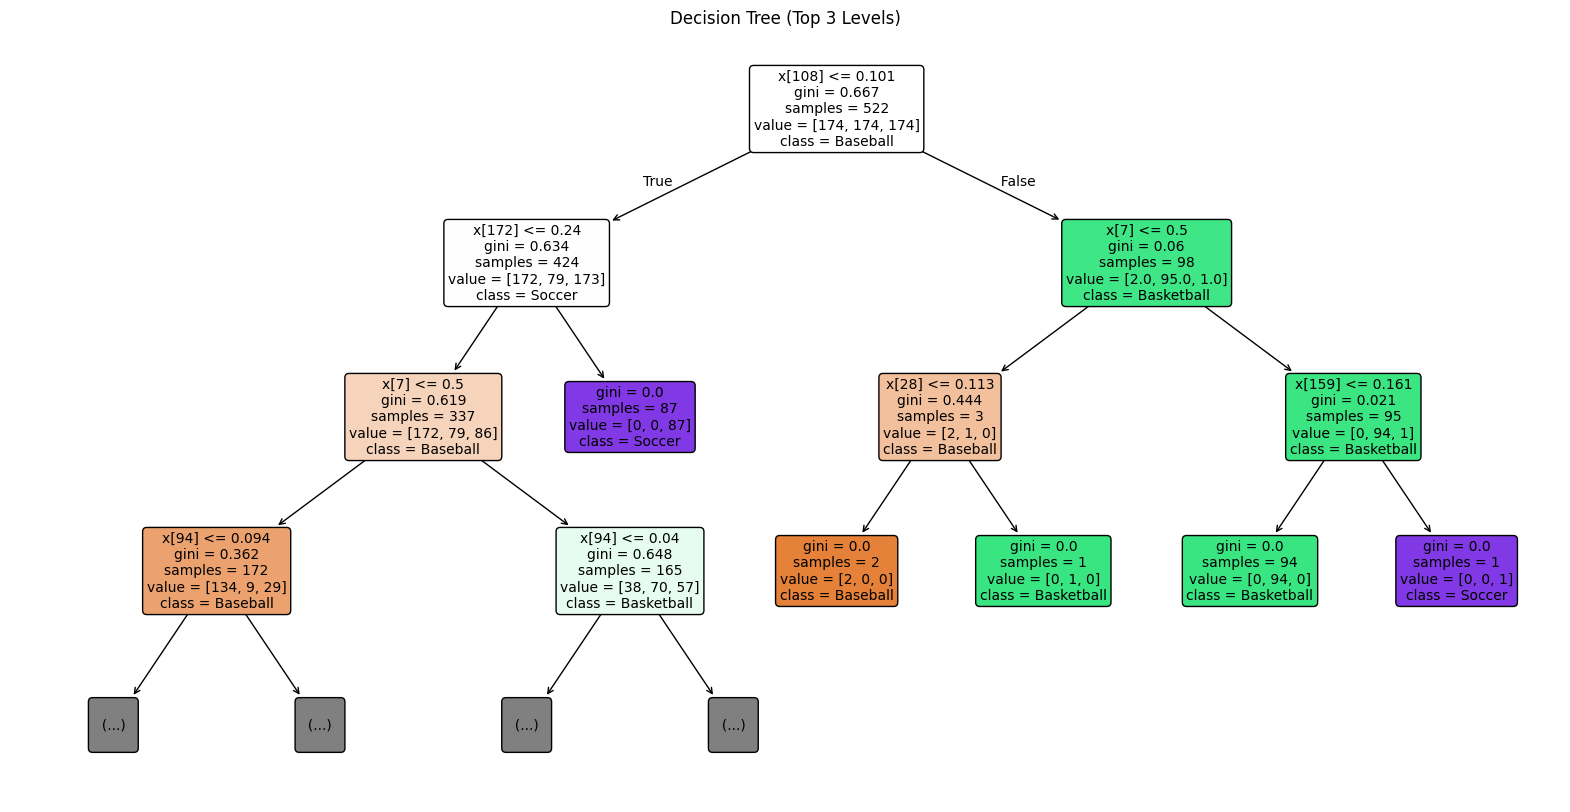

In [25]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Extract the fitted preprocessor and the decision tree from your best pipeline
fitted_preprocessor = best_model_pipeline.named_steps['preprocessor']
best_tree = best_model_pipeline.named_steps['tree']

# 2. Get the feature names generated by the ColumnTransformer (TF-IDF, Multi-hot, etc.)
try:
    feature_names = fitted_preprocessor.get_feature_names_out()
    # Clean up the names (sklearn adds prefixes like 'tfidf_song__' to the names)
    feature_names = [name.split('__')[-1] for name in feature_names]
except Exception as e:
    print(f"Could not extract feature names: {e}")
    feature_names = None

# 3. Plot the tree
plt.figure(figsize=(20, 10))
plot_tree(
    best_tree,
    feature_names=feature_names,
    class_names=best_tree.classes_.astype(str),
    filled=True,
    rounded=True,
    max_depth=3, # Limit visual depth so the plot is actually readable
    fontsize=10
)
plt.title("Decision Tree (Top 3 Levels)")
plt.show()

--- Final Test Accuracy: 0.8333 ---

--- Classification Report ---
              precision    recall  f1-score   support

    Baseball       0.75      0.88      0.81        58
  Basketball       0.87      0.90      0.88        58
      Soccer       0.91      0.72      0.81        58

    accuracy                           0.83       174
   macro avg       0.84      0.83      0.83       174
weighted avg       0.84      0.83      0.83       174



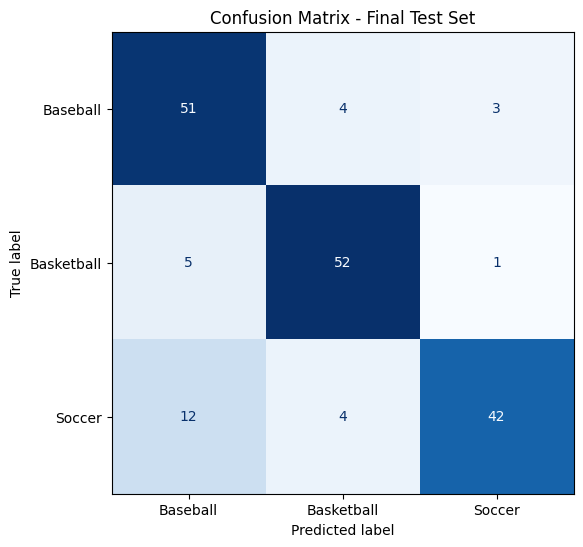

In [26]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# 1. Ensure the raw test set is loaded
test_df = pd.read_csv('../data/raw/test.csv')

# 2. Separate Features (X) and Target (y)
X_test = test_df.drop(columns=['label', 'id'])
y_test = test_df['label']

# 3. Predict using your tuned, leak-proof pipeline
test_preds = best_model_pipeline.predict(X_test)

# 4. Calculate overall accuracy
test_acc = accuracy_score(y_test, test_preds)
print(f"--- Final Test Accuracy: {test_acc:.4f} ---\n")

# 5. Print the detailed classification report (Precision, Recall, F1-Score)
print("--- Classification Report ---")
print(classification_report(y_test, test_preds))

# 6. Plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_estimator(
    best_model_pipeline, 
    X_test, 
    y_test, 
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title('Confusion Matrix - Final Test Set')
plt.show()

In [27]:
from sklearn.linear_model import LogisticRegression

# 1. Define hyperparameters to tune
# 'C' is the inverse of regularization strength (smaller = stronger regularization)
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

best_lr_acc = 0
best_lr_params = {}

print("--- Tuning Logistic Regression ---")

for c in C_values:
    # Build the pipeline reusing your exact same 'preprocessor'
    # max_iter=1000 is included to ensure the gradient descent solver converges 
    lr_pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('lr', LogisticRegression(C=c, max_iter=1000, random_state=42))
    ])
    
    # Fit entirely on training data
    lr_pipe.fit(X_train, y_train)
    
    # Evaluate entirely on unseen validation data
    preds = lr_pipe.predict(X_val)
    acc = accuracy_score(y_val, preds)
    
    print(f"C: {str(c).ljust(6)} -> Val Accuracy: {acc:.4f}")
    
    if acc > best_lr_acc:
        best_lr_acc = acc
        best_lr_params = {'C': c}
        
        # Save the best Logistic Regression pipeline
        best_lr_pipeline = lr_pipe

print("\n--- Best Validation Configuration (Logistic Regression) ---")
print(f"Parameters: {best_lr_params}")
print(f"Highest Validation Accuracy: {best_lr_acc:.4f}")

--- Tuning Logistic Regression ---
C: 0.01   -> Val Accuracy: 0.8448
C: 0.1    -> Val Accuracy: 0.8678
C: 1.0    -> Val Accuracy: 0.8736
C: 10.0   -> Val Accuracy: 0.8678
C: 100.0  -> Val Accuracy: 0.8621

--- Best Validation Configuration (Logistic Regression) ---
Parameters: {'C': 1.0}
Highest Validation Accuracy: 0.8736


--- Logistic Regression Final Test Accuracy: 0.8793 ---

--- Classification Report ---
              precision    recall  f1-score   support

    Baseball       0.87      0.83      0.85        58
  Basketball       0.89      0.95      0.92        58
      Soccer       0.88      0.86      0.87        58

    accuracy                           0.88       174
   macro avg       0.88      0.88      0.88       174
weighted avg       0.88      0.88      0.88       174



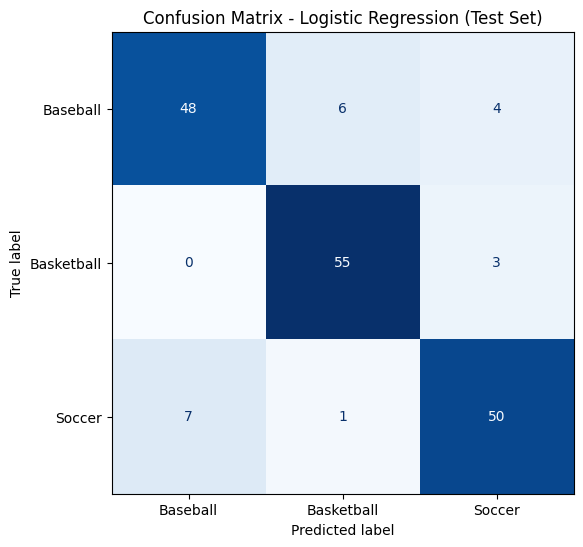

In [28]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Predict using the tuned Logistic Regression pipeline
lr_test_preds = best_lr_pipeline.predict(X_test)

# 2. Calculate overall accuracy
lr_test_acc = accuracy_score(y_test, lr_test_preds)
print(f"--- Logistic Regression Final Test Accuracy: {lr_test_acc:.4f} ---\n")

# 3. Print the detailed classification report
print("--- Classification Report ---")
print(classification_report(y_test, lr_test_preds))

# 4. Plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_estimator(
    best_lr_pipeline, 
    X_test, 
    y_test, 
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title('Confusion Matrix - Logistic Regression (Test Set)')
plt.show()

In [29]:
from sklearn.neural_network import MLPClassifier

# 1. Define hyperparameters to tune
# hidden_layer_sizes: controls network depth and width. (50,) is 1 layer of 50 neurons. (50, 25) is 2 layers.
# alpha: L2 regularization term to prevent overfitting on your sparse text features.
hidden_layers = [(50,), (100,), (50, 25)]
alphas = [0.0001, 0.01, 0.1]

best_nn_acc = 0
best_nn_params = {}

print("--- Tuning Neural Network (MLP) ---")

for layers in hidden_layers:
    for a in alphas:
        # Build the pipeline reusing your exact same 'preprocessor'
        # max_iter=1000 allows the backpropagation solver (Adam) enough time to converge
        nn_pipe = Pipeline([
            ('preprocessor', preprocessor),
            ('nn', MLPClassifier(hidden_layer_sizes=layers, alpha=a, max_iter=1000, random_state=42))
        ])
        
        # Fit entirely on training data
        nn_pipe.fit(X_train, y_train)
        
        # Evaluate entirely on unseen validation data
        preds = nn_pipe.predict(X_val)
        acc = accuracy_score(y_val, preds)
        
        print(f"Layers: {str(layers).ljust(8)} | Alpha: {str(a).ljust(6)} -> Val Accuracy: {acc:.4f}")
        
        if acc > best_nn_acc:
            best_nn_acc = acc
            best_nn_params = {'hidden_layer_sizes': layers, 'alpha': a}
            
            # Save the best Neural Network pipeline
            best_nn_pipeline = nn_pipe

print("\n--- Best Validation Configuration (Neural Network) ---")
print(f"Parameters: {best_nn_params}")
print(f"Highest Validation Accuracy: {best_nn_acc:.4f}")

--- Tuning Neural Network (MLP) ---
Layers: (50,)    | Alpha: 0.0001 -> Val Accuracy: 0.8506
Layers: (50,)    | Alpha: 0.01   -> Val Accuracy: 0.8621
Layers: (50,)    | Alpha: 0.1    -> Val Accuracy: 0.8678
Layers: (100,)   | Alpha: 0.0001 -> Val Accuracy: 0.8506
Layers: (100,)   | Alpha: 0.01   -> Val Accuracy: 0.8621
Layers: (100,)   | Alpha: 0.1    -> Val Accuracy: 0.8678
Layers: (50, 25) | Alpha: 0.0001 -> Val Accuracy: 0.8448
Layers: (50, 25) | Alpha: 0.01   -> Val Accuracy: 0.8448
Layers: (50, 25) | Alpha: 0.1    -> Val Accuracy: 0.8621

--- Best Validation Configuration (Neural Network) ---
Parameters: {'hidden_layer_sizes': (50,), 'alpha': 0.1}
Highest Validation Accuracy: 0.8678


--- Neural Network Final Test Accuracy: 0.9023 ---

--- Classification Report ---
              precision    recall  f1-score   support

    Baseball       0.93      0.86      0.89        58
  Basketball       0.89      0.95      0.92        58
      Soccer       0.90      0.90      0.90        58

    accuracy                           0.90       174
   macro avg       0.90      0.90      0.90       174
weighted avg       0.90      0.90      0.90       174



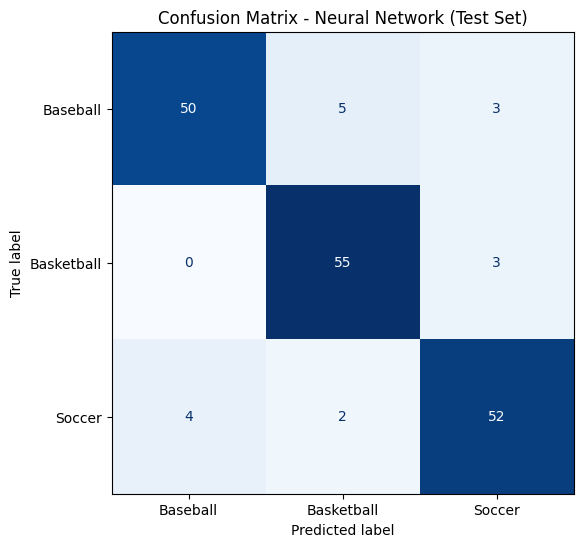

In [30]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Predict using the tuned Neural Network pipeline
nn_test_preds = best_nn_pipeline.predict(X_test)

# 2. Calculate overall accuracy
nn_test_acc = accuracy_score(y_test, nn_test_preds)
print(f"--- Neural Network Final Test Accuracy: {nn_test_acc:.4f} ---\n")

# 3. Print the detailed classification report
print("--- Classification Report ---")
print(classification_report(y_test, nn_test_preds))

# 4. Plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_estimator(
    best_nn_pipeline, 
    X_test, 
    y_test, 
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title('Confusion Matrix - Neural Network (Test Set)')
plt.show()

In [31]:
from sklearn.ensemble import RandomForestClassifier

# 1. Define hyperparameters to tune
# n_estimators: number of trees in the forest
# max_depth: limits how deep each individual tree can grow
n_estimators_list = [50, 100, 200]
depths = [5, 10, 15, None]

best_rf_acc = 0
best_rf_params = {}

print("--- Tuning Random Forest ---")

for n in n_estimators_list:
    for d in depths:
        # Build the pipeline reusing your exact same 'preprocessor'
        # n_jobs=-1 uses all available CPU cores to train the trees in parallel
        rf_pipe = Pipeline([
            ('preprocessor', preprocessor),
            ('rf', RandomForestClassifier(n_estimators=n, max_depth=d, random_state=42, n_jobs=-1))
        ])
        
        # Fit entirely on training data
        rf_pipe.fit(X_train, y_train)
        
        # Evaluate entirely on unseen validation data
        preds = rf_pipe.predict(X_val)
        acc = accuracy_score(y_val, preds)
        
        print(f"Trees: {str(n).ljust(4)} | Max Depth: {str(d).ljust(4)} -> Val Accuracy: {acc:.4f}")
        
        if acc > best_rf_acc:
            best_rf_acc = acc
            best_rf_params = {'n_estimators': n, 'max_depth': d}
            
            # Save the best Random Forest pipeline
            best_rf_pipeline = rf_pipe

print("\n--- Best Validation Configuration (Random Forest) ---")
print(f"Parameters: {best_rf_params}")
print(f"Highest Validation Accuracy: {best_rf_acc:.4f}")

--- Tuning Random Forest ---
Trees: 50   | Max Depth: 5    -> Val Accuracy: 0.8678
Trees: 50   | Max Depth: 10   -> Val Accuracy: 0.8908
Trees: 50   | Max Depth: 15   -> Val Accuracy: 0.8793
Trees: 50   | Max Depth: None -> Val Accuracy: 0.8851
Trees: 100  | Max Depth: 5    -> Val Accuracy: 0.8736
Trees: 100  | Max Depth: 10   -> Val Accuracy: 0.9023
Trees: 100  | Max Depth: 15   -> Val Accuracy: 0.8793
Trees: 100  | Max Depth: None -> Val Accuracy: 0.8736
Trees: 200  | Max Depth: 5    -> Val Accuracy: 0.8851
Trees: 200  | Max Depth: 10   -> Val Accuracy: 0.9080
Trees: 200  | Max Depth: 15   -> Val Accuracy: 0.9080
Trees: 200  | Max Depth: None -> Val Accuracy: 0.9080

--- Best Validation Configuration (Random Forest) ---
Parameters: {'n_estimators': 200, 'max_depth': 10}
Highest Validation Accuracy: 0.9080


--- Random Forest Final Test Accuracy: 0.8793 ---

--- Classification Report ---
              precision    recall  f1-score   support

    Baseball       0.84      0.91      0.88        58
  Basketball       0.85      0.90      0.87        58
      Soccer       0.96      0.83      0.89        58

    accuracy                           0.88       174
   macro avg       0.88      0.88      0.88       174
weighted avg       0.88      0.88      0.88       174



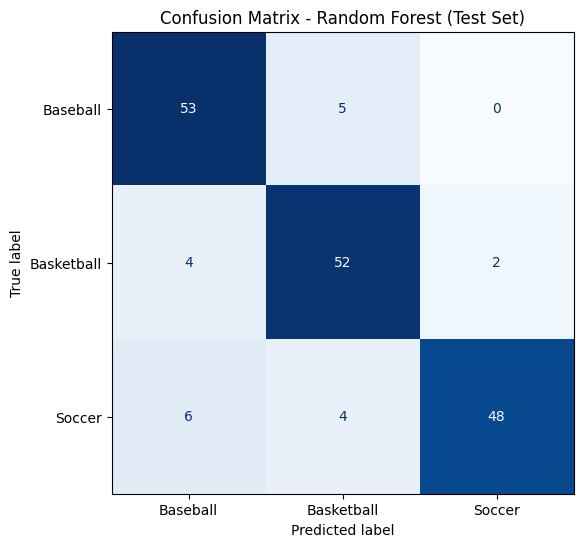

In [32]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Predict using the tuned Random Forest pipeline
rf_test_preds = best_rf_pipeline.predict(X_test)

# 2. Calculate overall accuracy
rf_test_acc = accuracy_score(y_test, rf_test_preds)
print(f"--- Random Forest Final Test Accuracy: {rf_test_acc:.4f} ---\n")

# 3. Print the detailed classification report
print("--- Classification Report ---")
print(classification_report(y_test, rf_test_preds))

# 4. Plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_estimator(
    best_rf_pipeline, 
    X_test, 
    y_test, 
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title('Confusion Matrix - Random Forest (Test Set)')
plt.show()

In [33]:
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import FunctionTransformer

# GaussianNB requires dense data, but our TF-IDF and CountVectorizers output sparse matrices.
# This simple transformer converts the sparse matrix back into a standard dense array.
def to_dense(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    return X

to_dense_transformer = FunctionTransformer(to_dense, accept_sparse=True)

# 1. Define hyperparameters to tune
# var_smoothing adds a small variance to the calculation for stability
smoothing_values = [1e-9, 1e-5, 1e-3, 1e-1]

best_nb_acc = 0
best_nb_params = {}

print("--- Tuning Gaussian Naive Bayes ---")

for v in smoothing_values:
    # Build the pipeline reusing your exact same 'preprocessor'
    # We use GaussianNB because StandardScaler creates negative values, which breaks MultinomialNB
    nb_pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('to_dense', to_dense_transformer),
        ('nb', GaussianNB(var_smoothing=v))
    ])
    
    # Fit entirely on training data
    nb_pipe.fit(X_train, y_train)
    
    # Evaluate entirely on unseen validation data
    preds = nb_pipe.predict(X_val)
    acc = accuracy_score(y_val, preds)
    
    print(f"Var Smoothing: {str(v).ljust(6)} -> Val Accuracy: {acc:.4f}")
    
    if acc > best_nb_acc:
        best_nb_acc = acc
        best_nb_params = {'var_smoothing': v}
        
        # Save the best Naive Bayes pipeline
        best_nb_pipeline = nb_pipe

print("\n--- Best Validation Configuration (Naive Bayes) ---")
print(f"Parameters: {best_nb_params}")
print(f"Highest Validation Accuracy: {best_nb_acc:.4f}")

--- Tuning Gaussian Naive Bayes ---
Var Smoothing: 1e-09  -> Val Accuracy: 0.7299
Var Smoothing: 1e-05  -> Val Accuracy: 0.7586
Var Smoothing: 0.001  -> Val Accuracy: 0.7931
Var Smoothing: 0.1    -> Val Accuracy: 0.8793

--- Best Validation Configuration (Naive Bayes) ---
Parameters: {'var_smoothing': 0.1}
Highest Validation Accuracy: 0.8793


--- Naive Bayes Final Test Accuracy: 0.8793 ---

--- Classification Report ---
              precision    recall  f1-score   support

    Baseball       0.85      0.90      0.87        58
  Basketball       0.83      0.93      0.88        58
      Soccer       0.98      0.81      0.89        58

    accuracy                           0.88       174
   macro avg       0.89      0.88      0.88       174
weighted avg       0.89      0.88      0.88       174



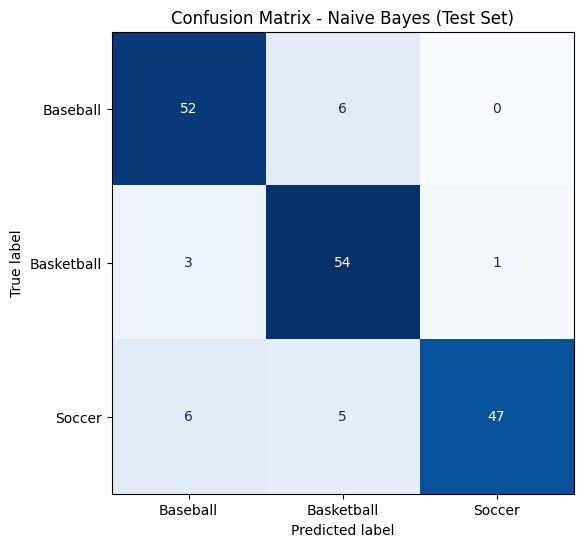

In [34]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Predict using the tuned Naive Bayes pipeline
nb_test_preds = best_nb_pipeline.predict(X_test)

# 2. Calculate overall accuracy
nb_test_acc = accuracy_score(y_test, nb_test_preds)
print(f"--- Naive Bayes Final Test Accuracy: {nb_test_acc:.4f} ---\n")

# 3. Print the detailed classification report
print("--- Classification Report ---")
print(classification_report(y_test, nb_test_preds))

# 4. Plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_estimator(
    best_nb_pipeline, 
    X_test, 
    y_test, 
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title('Confusion Matrix - Naive Bayes (Test Set)')
plt.show()